# Определение стоимости автомобилей

Сервис по продаже автомобилей с пробегом «Не бит, не крашен» разрабатывает приложение для привлечения новых клиентов. В нём можно быстро узнать рыночную стоимость своего автомобиля. В вашем распоряжении исторические данные: технические характеристики, комплектации и цены автомобилей. Вам нужно построить модель для определения стоимости. 

Заказчику важны:

- качество предсказания;
- скорость предсказания;
- время обучения.

## Подготовка данных

Для начала подгрузим требуемые библиотека

In [1]:
!pip install phik -q

In [2]:
!pip install category_encoders -q

In [3]:
!pip install scikit-learn==1.1.3 -q

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import time

from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, StandardScaler, MinMaxScaler, RobustScaler
from category_encoders import CatBoostEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from phik import phik_matrix
from phik.report import plot_correlation_matrix

from sklearn.metrics import mean_squared_error,make_scorer

from catboost import CatBoostRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [5]:
RANDOM_STATE = 42
TEST_SIZE = 0.25

Напишем класс для исследовательского анализа данных

In [6]:
class EDA:
    
    def __init__(self, filepath):
        self.filepath = filepath
        try:
            self.df = self.read_data()
            print('Данные загружены')
        except:
            self.df is None
            print('Все плохо')
    
    def read_data(self):
        if '.csv' in self.filepath:
            return pd.read_csv(self.filepath, encoding='utf-8')
        elif 'xlsx' in self.filepath:
            return pd.read_excel(self.filepath, encoding='utf-8')
        
    def intro(self):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Первые пять строк и базовая инфа')
        display(self.df.head(5))
        display(self.df.describe())
        self.df.info()
        
    def feature_display(self, int_cols, dis_cols, cat_cols):
        if self.df is None:
            print('Все плохо')
            return
        
        print('Диаграммы размаха и гистограммы непрерывных признаков')
        for column in int_cols:
            fig, ax = plt.subplots(figsize=(8, 5))
            sns.histplot(self.df, x=column,
                 kde=True, kde_kws={'bw_method': 0.6}, edgecolor='white', ax=ax)
            ax.set_title(f'Распределение признака\n«{column}»')
            ax.set_xlabel(column)
            ax.set_ylabel('Количество')
            plt.show()
        
        print('Столбчатые диаграммы дискретных признаков')        
        for column in dis_cols:
            plt.title(column)
            plt.bar(self.df[column].value_counts().index, self.df[column].value_counts().values)
            plt.show()
            
        print('Столбчатые диаграммы для категориальных признаков')
        for column in cat_cols:
            counts = self.df[column].value_counts()
            plt.figure(figsize=(10,4))
            sns.barplot(x=counts.sort_values(ascending=False).index, 
                        y=counts.values, 
                        palette="viridis")
            plt.xticks(rotation=90)
            plt.tight_layout()
            plt.title(column)
            plt.show()
        
    def phik_matrix(self,int_cols):
        phik_overview = self.df.drop(['PostalCode','NumberOfPictures','DateCrawled','LastSeen'],axis=1).sample(n=20000,random_state=RANDOM_STATE).phik_matrix(interval_cols=int_cols)
        plt.figure(figsize=(20, 12))
        sns.heatmap(phik_overview, annot=True, cmap="coolwarm", fmt=".2f", linewidths=.5, center=0)
        plt.title("Матрица корреляций")
        plt.show()

Считаем наши данные

In [7]:
data = EDA('/datasets/autos.csv')
df_main = data.df

Данные загружены


Давайте ознакомимся с данными

In [8]:
data.intro()

Первые пять строк и базовая инфа


,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21


,Price,RegistrationYear,Power,Kilometer,RegistrationMonth,NumberOfPictures,PostalCode
count,354369.000000,354369.000000,354369.000000,354369.000000,354369.000000,354369.0,354369.000000
mean,4416.656776,2004.234448,110.094337,128211.172535,5.714645,0.0,50508.689087
std,4514.158514,90.227958,189.850405,37905.341530,3.726421,0.0,25783.096248
min,0.000000,1000.000000,0.000000,5000.000000,0.000000,0.0,1067.000000
25%,1050.000000,1999.000000,69.000000,125000.000000,3.000000,0.0,30165.000000
50%,2700.000000,2003.000000,105.000000,150000.000000,6.000000,0.0,49413.000000
75%,6400.000000,2008.000000,143.000000,150000.000000,9.000000,0.0,71083.000000
max,20000.000000,9999.000000,20000.000000,150000.000000,12.000000,0.0,99998.000000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  Repaired           283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  LastSeen           354369 non-null  object
dtypes: int64(7), object(

Сразу видно, что есть пропуски, причем в разных местах, в разных признаках, вначале заполним эти пропуски заглушкой "Unknown"

In [9]:
df_main = df_main.fillna(value='Unknown')
data.df = df_main

Распределим признаки по категориям, для дальнейшего анализа

In [10]:
cat_cols = ['VehicleType',
            'Gearbox',
            'Model',
            'FuelType',
            'Brand',
            'Repaired']

dis_cols = ['RegistrationMonth',
            'NumberOfPictures',
            'RegistrationYear']

int_cols = ['Price',
            'Power',
            'Kilometer']

Избавимся от явных дубликатов

In [11]:
print(df_main.duplicated().count())

354369


In [12]:
df_main = df_main.drop_duplicates()

Посмотрим, что по неявным дубликатам

In [13]:
for column in cat_cols:
    print('Значения признака и их упоминания у признака', column)
    display(df_main[column].value_counts())
    print()

Значения признака и их упоминания у признака VehicleType


sedan          91457
small          79830
wagon          65165
Unknown        37490
bus            28775
convertible    20203
coupe          16161
suv            11996
other           3288
Name: VehicleType, dtype: int64


Значения признака и их упоминания у признака Gearbox


manual     268249
auto        66283
Unknown     19833
Name: Gearbox, dtype: int64


Значения признака и их упоминания у признака Model


golf                  29232
other                 24420
3er                   19761
Unknown               19705
polo                  13066
                      ...  
i3                        8
serie_3                   4
rangerover                4
serie_1                   2
range_rover_evoque        2
Name: Model, Length: 251, dtype: int64

... (2 outputs left out)


Значения признака и их упоминания у признака Brand


volkswagen        77012
opel              39931
bmw               36914
mercedes_benz     32044
audi              29456
ford              25179
renault           17927
peugeot           10998
fiat               9643
seat               6907
mazda              5615
skoda              5500
smart              5246
citroen            5148
nissan             4941
toyota             4606
hyundai            3587
sonstige_autos     3374
volvo              3210
mini               3202
mitsubishi         3022
honda              2817
kia                2465
suzuki             2322
alfa_romeo         2314
chevrolet          1754
chrysler           1439
dacia               900
daihatsu            806
subaru              762
porsche             758
jeep                677
trabant             589
land_rover          545
daewoo              542
saab                526
jaguar              505
rover               486
lancia              471
lada                225
Name: Brand, dtype: int64


Значения признака и их упоминания у признака Repaired


no         247158
Unknown     71154
yes         36053
Name: Repaired, dtype: int64

Все таки нявные дубликаты есть

In [14]:
df_main = df_main.copy() 
df_main.loc[:, 'FuelType'] = df_main['FuelType'].str.replace('petrol', 'gasoline')
data.df = df_main

С неявными разобрались, давайте построим графики для наших распределений(диаграммы размаха, гистограммы, столбчатые диаграммы)

Диаграммы размаха и гистограммы непрерывных признаков


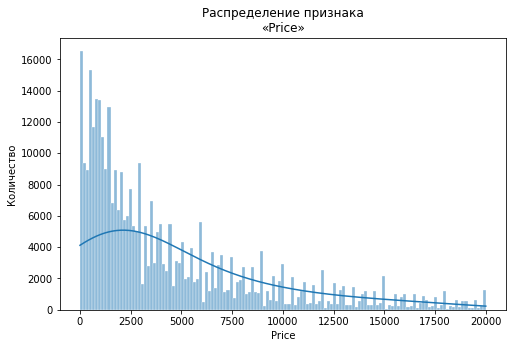

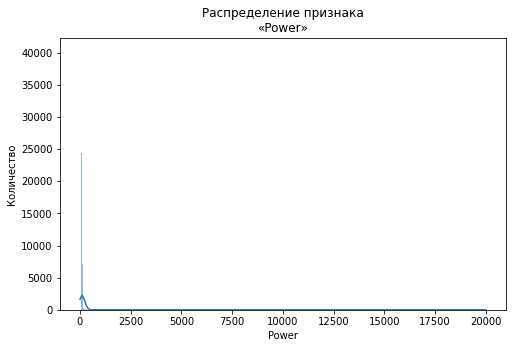

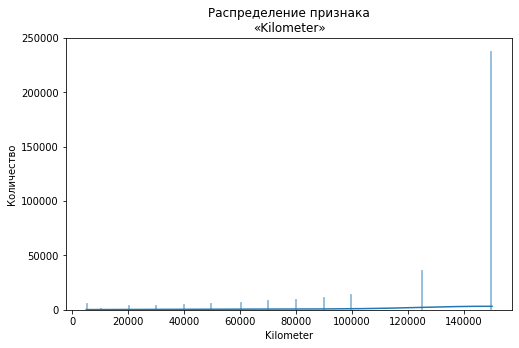

Столбчатые диаграммы дискретных признаков


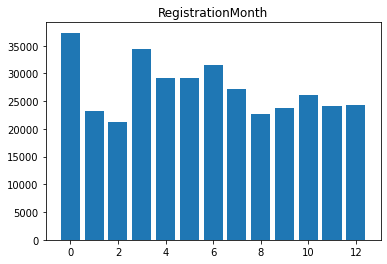

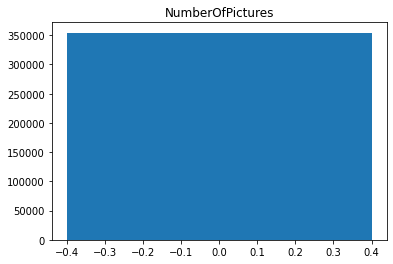

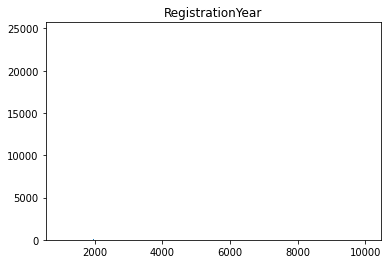

Столбчатые диаграммы для категориальных признаков


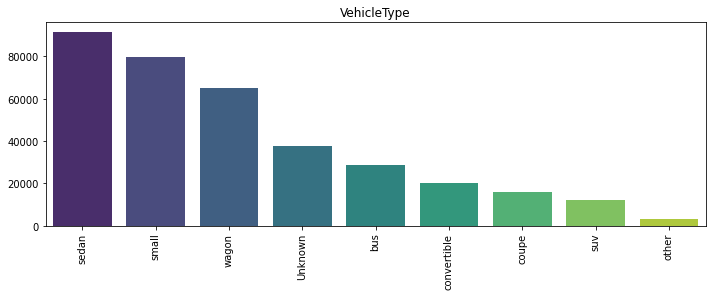

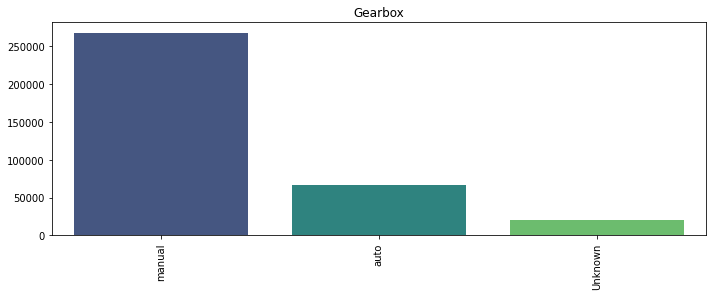

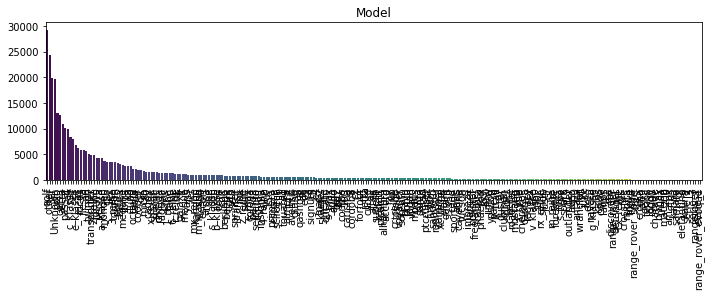

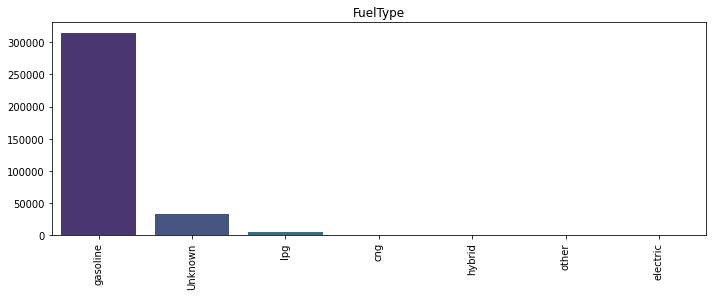

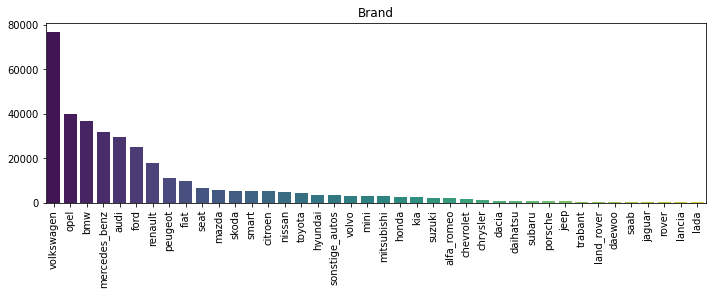

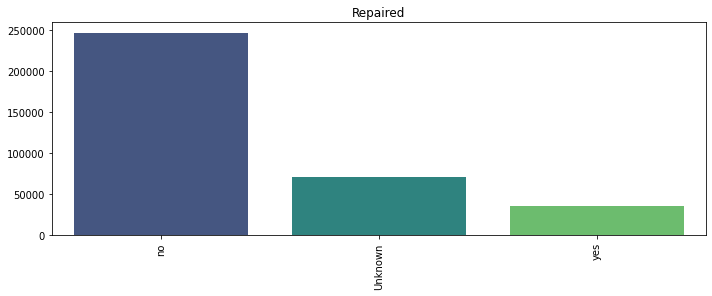

In [15]:
data.feature_display(int_cols,dis_cols,cat_cols)

In [16]:
df_main = df_main.query('10<=Power<=2000')
df_main = df_main.query('1900<=RegistrationYear<=2026')
df_main = df_main.query('0<Price')

Нашли некоторое количество аномалий и исправили их. Таргетный признак имеет ассиматрию с пиком в значениях близких к 0. Признак с мощностью имеет схожее распределению но с более выраженной ассиметрией, потому что в значения близкие к нулю имеют крайне маленькую численность. Признак пробега имеет отрицательную ассиметрию с пиком в значениях более 140000. Распределение месяца регистрации имеет равномерное распределение. Признак с количеством картинок полностью состоит из нулей. По поводу категориальных признаков, самые многочисленные категории в признаке с типом машины это седан, легковая и фургон. Подавляющее большинство людей катаются на механической коробке передач. Подавляющее большинство машин работают на бензине. Большинство машин произведены volkswagen, opel, bmw, mercedez, audi, ford и renault. Большинство машин не были в ремонте

Далее проведем корреляционный анализ

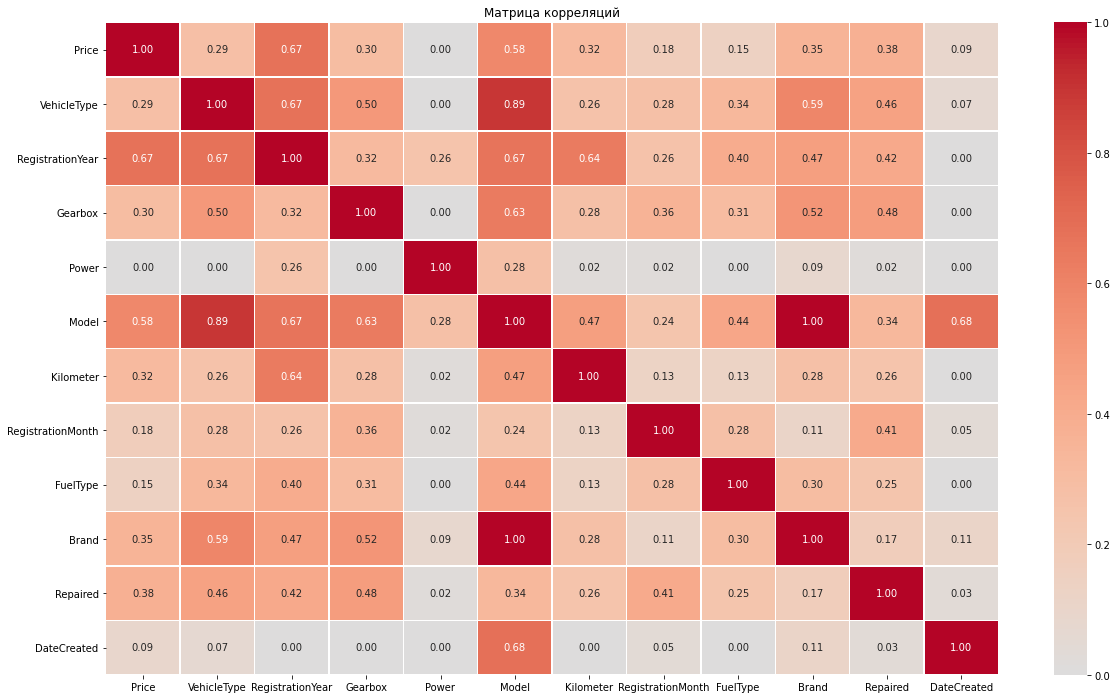

In [17]:
data.phik_matrix(int_cols)

Признак мощности имеет околонулевую корреляцию с таргетной переменной. Также важный момент это то, что брэнд и модель имеют стопроцентную корреляцию, следовательно оставляем только один из них для обучения

## Обучение моделей

Отберем признаки для обучения: опускаем мощность и брэнд по оглашенным в коррелционном анализе причинам, также стоит убрать все даты связанные с сервисом, так как они не влияют на стоимость напрямую, как и почтрвый индекс

Разделим данные на тренировочную и тестовую выборки

In [18]:
ML_df = df_main.drop(['DateCrawled',
                  'Power',
                  'Brand',
                  'DateCreated',
                  'NumberOfPictures',
                  'PostalCode',
                  'LastSeen'],
                  axis=1)

ML_df = ML_df.drop_duplicates()

X = ML_df.drop('Price',axis=1)
y = ML_df['Price']

X_train, X_test, y_train, y_test = train_test_split(X,y,random_state=RANDOM_STATE,test_size=TEST_SIZE)

catboost_cols = ['VehicleType','Gearbox','Model','FuelType','Repaired']
num_cols = ['RegistrationYear','Kilometer','RegistrationMonth',]

Напишем пайплайн для обработки данных

In [19]:
data_preprocessor = ColumnTransformer(
    [('catboost', CatBoostEncoder(random_state=RANDOM_STATE,verbose=False), catboost_cols),
     ('num', MinMaxScaler(), num_cols)
    ], 
    remainder='passthrough')

Объединим это все в финальный пайплайн и обозначим гиперпараметры для нашего подбора

In [20]:
pipe_final = Pipeline([
    ('preprocessor', data_preprocessor),
    ('models', DecisionTreeRegressor(random_state=RANDOM_STATE))
])


param_grid = [
    {
        'models': [lgb.LGBMRegressor(random_state=RANDOM_STATE,time_out=60,verbose=-1)],
        'models__n_estimators': [100, 300, 500],
        'models__learning_rate': [0.01, 0.05, 0.1],
        'models__num_leaves': [20, 30, 40],
        'models__max_depth': [-1, 5, 10],
        'preprocessor__num': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough'] 
    },

    {
        'models': [DecisionTreeRegressor(random_state=RANDOM_STATE)],
        'models__max_depth': range(2,5),
        'models__max_features': range(2,5),
        'preprocessor__num': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough']  
    },
     
    {
        'models': [CatBoostRegressor(random_state=RANDOM_STATE,early_stopping_rounds=50)],
        'models__iterations': [100, 300, 500],
        'models__learning_rate': [0.01, 0.05, 0.1], 
        'models__depth': [4, 6, 8],
        'preprocessor__num': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough']   
    },

    {
        'models': [LinearRegression()],
        'preprocessor__num': [StandardScaler(), MinMaxScaler(), RobustScaler(), 'passthrough']  
    }
]

Подберем наши гиперпараметры

In [21]:
%%time
r_search = RandomizedSearchCV(
    pipe_final, 
    param_grid, 
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=RANDOM_STATE,
    n_jobs=-1
)
r_search.fit(X_train, y_train)
print('Лучшая модель')
print()
print(r_search.best_estimator_)
print()
print ('Метрика лучшей модели', r_search.best_score_)
print()
print(r_search.best_params_)

preds = r_search.predict(X_test)

0:	learn: 4356.5961430	total: 73.8ms	remaining: 22.1s
1:	learn: 4139.0311594	total: 93.5ms	remaining: 13.9s
2:	learn: 3942.3443499	total: 113ms	remaining: 11.2s
3:	learn: 3774.3723905	total: 133ms	remaining: 9.83s
4:	learn: 3627.5853717	total: 152ms	remaining: 8.97s
5:	learn: 3492.0635378	total: 170ms	remaining: 8.34s
6:	learn: 3380.1304144	total: 190ms	remaining: 7.95s
7:	learn: 3276.0830257	total: 208ms	remaining: 7.6s
8:	learn: 3185.6517938	total: 227ms	remaining: 7.35s
9:	learn: 3105.4565070	total: 246ms	remaining: 7.13s
10:	learn: 3036.4911854	total: 264ms	remaining: 6.94s
11:	learn: 2974.3480435	total: 283ms	remaining: 6.8s
12:	learn: 2918.5480419	total: 301ms	remaining: 6.65s
13:	learn: 2871.9969719	total: 320ms	remaining: 6.54s
14:	learn: 2821.4388642	total: 338ms	remaining: 6.41s
15:	learn: 2779.1174254	total: 357ms	remaining: 6.33s
16:	learn: 2741.6920124	total: 375ms	remaining: 6.24s
17:	learn: 2707.7764023	total: 394ms	remaining: 6.17s
18:	learn: 2679.1002458	total: 413ms	r

In [22]:
print('Время обучения: ',r_search.cv_results_['mean_fit_time'][r_search.best_index_])
print('Время предсказания: ',r_search.cv_results_['mean_score_time'][r_search.best_index_])

Время обучения:  18.97390947341919
Время предсказания:  1.1386183261871339


## Анализ моделей

Значение метрики rmse равно 2085, что соответствует нашим критериям. Лучше всего себя показала модель LGBMRegressor с параметрами: n_estimators=500, num_leaves=30, learning_rate=0.1, max_depth=-1. Время обучения получилось 13 секунд, а время предсказания 1 секунда. Для наших задач данной скорости хватает. Хотя время подбора гиперапараметров получилось довольно долгим, но точность того  стоит, потому что приносит нам деньги, можно было бы и через optuna погонять модели пару часов, получилось бы еще точнее, но и дольше в пару раз

## Чек-лист проверки

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Выполнена загрузка и подготовка данных
- [x]  Выполнено обучение моделей
- [x]  Есть анализ скорости работы и качества моделей